In [22]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)

TensorFlow: 2.21.0
OpenCV: 5.0.0


In [23]:
import os

dataset_path = r"C:\Users\yoush\OneDrive\Desktop\PlantDiseaseDetection\PlantVillage"

classes = os.listdir(dataset_path)

print(classes)

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'PlantVillage', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [24]:
for disease in classes:
    folder_path = os.path.join(dataset_path, disease)

    if os.path.isdir(folder_path):
        print(disease, ":", len(os.listdir(folder_path)), "images")

Pepper__bell___Bacterial_spot : 920 images
Pepper__bell___healthy : 1478 images
PlantVillage : 15 images
Potato___Early_blight : 1000 images
Potato___healthy : 152 images
Potato___Late_blight : 1000 images
Tomato_Bacterial_spot : 2127 images
Tomato_Early_blight : 1000 images
Tomato_healthy : 1591 images
Tomato_Late_blight : 1909 images
Tomato_Leaf_Mold : 952 images
Tomato_Septoria_leaf_spot : 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite : 1676 images
Tomato__Target_Spot : 1404 images
Tomato__Tomato_mosaic_virus : 373 images
Tomato__Tomato_YellowLeaf__Curl_Virus : 3209 images


In [25]:
extra_path = os.path.join(
    dataset_path,
    "PlantVillage"
)

print(os.listdir(extra_path))

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [26]:
import os
import pandas as pd

image_extensions = (".jpg", ".jpeg", ".png")

data = []

for disease in classes:

    folder_path = os.path.join(
        dataset_path,
        disease
    )

    if disease == "PlantVillage":
        continue

    if os.path.isdir(folder_path):

        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(image_extensions)
        ]

        data.append({
            "Disease": disease,
            "Total Images": len(images)
        })

df = pd.DataFrame(data)

print(df.to_string(index=False))

print("\nTotal Images:", df["Total Images"].sum())
print("Total Classes:", len(df))

                                    Disease  Total Images
              Pepper__bell___Bacterial_spot           920
                     Pepper__bell___healthy          1478
                      Potato___Early_blight          1000
                           Potato___healthy           152
                       Potato___Late_blight          1000
                      Tomato_Bacterial_spot          2127
                        Tomato_Early_blight          1000
                             Tomato_healthy          1591
                         Tomato_Late_blight          1909
                           Tomato_Leaf_Mold           952
                  Tomato_Septoria_leaf_spot          1771
Tomato_Spider_mites_Two_spotted_spider_mite          1676
                        Tomato__Target_Spot          1404
                Tomato__Tomato_mosaic_virus           373
      Tomato__Tomato_YellowLeaf__Curl_Virus          3208

Total Images: 20561
Total Classes: 15


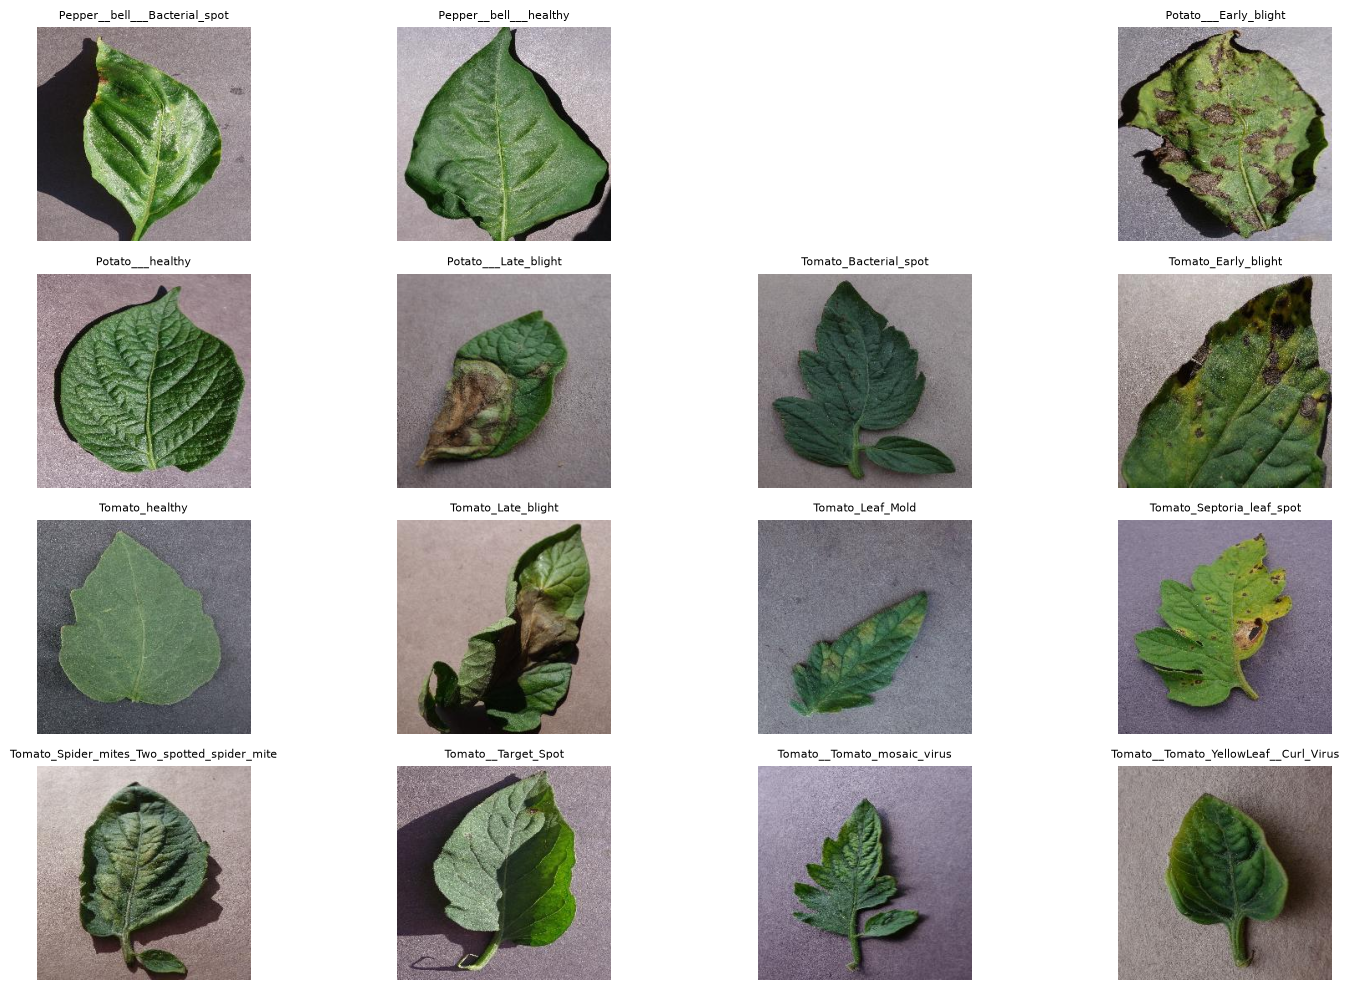

In [27]:
import cv2
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(15, 10))

for i, disease in enumerate(classes):

    if disease == "PlantVillage":
        continue

    folder_path = os.path.join(
        dataset_path,
        disease
    )

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    if not image_files:
        continue

    image_path = os.path.join(
        folder_path,
        image_files[0]
    )

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(4, 4, i + 1)

    plt.imshow(image)

    plt.title(disease, fontsize=8)

    plt.axis("off")

plt.tight_layout()
plt.show()

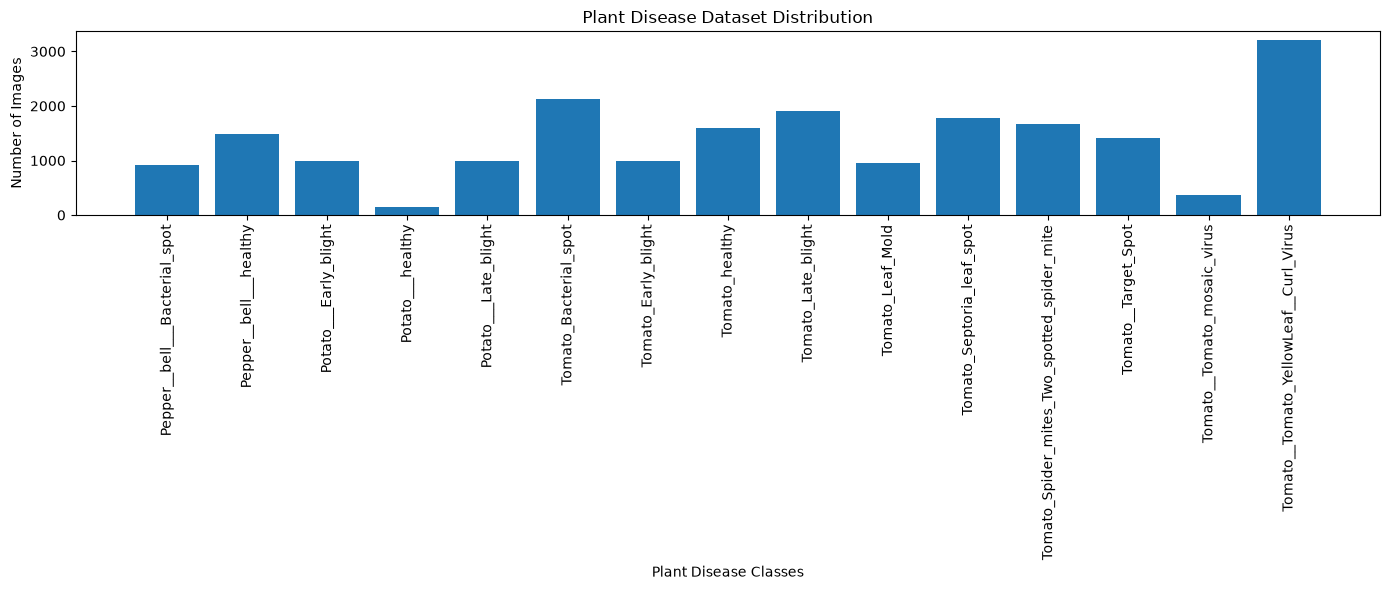

In [28]:
plt.figure(figsize=(14, 6))

plt.bar(
    df["Disease"],
    df["Total Images"]
)

plt.xticks(rotation=90)

plt.xlabel("Plant Disease Classes")
plt.ylabel("Number of Images")

plt.title("Plant Disease Dataset Distribution")

plt.tight_layout()

plt.show()

In [29]:
image_sizes = []

for disease in classes:

    if disease == "PlantVillage":
        continue

    folder_path = os.path.join(
        dataset_path,
        disease
    )

    for file in os.listdir(folder_path):

        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            image_path = os.path.join(
                folder_path,
                file
            )

            image = cv2.imread(image_path)

            if image is not None:
                height, width, channels = image.shape

                image_sizes.append(
                    (width, height)
                )

print("Total readable images:", len(image_sizes))
print("Unique image dimensions:", set(image_sizes))

Total readable images: 20561
Unique image dimensions: {(256, 256)}


In [30]:
import os
import shutil
from sklearn.model_selection import train_test_split

# Original dataset
dataset_path = r"C:\Users\yoush\OneDrive\Desktop\PlantDiseaseDetection\PlantVillage"

# Output dataset
output_path = r"C:\Users\yoush\OneDrive\Desktop\PlantDiseaseDetection\dataset_split"

# Image extensions
extensions = (".jpg", ".jpeg", ".png")

# Create output folders
for split in ["train", "val", "test"]:
    os.makedirs(
        os.path.join(output_path, split),
        exist_ok=True
    )

# Get disease classes
classes = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
    and folder != "PlantVillage"
]

for disease in classes:

    folder_path = os.path.join(dataset_path, disease)

    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(extensions)
    ]

    # 80% training, 20% remaining
    train_images, remaining = train_test_split(
        images,
        test_size=0.20,
        random_state=42
    )

    # Divide remaining into 10% validation and 10% testing
    val_images, test_images = train_test_split(
        remaining,
        test_size=0.50,
        random_state=42
    )

    split_data = {
        "train": train_images,
        "val": val_images,
        "test": test_images
    }

    for split, files in split_data.items():

        destination = os.path.join(
            output_path, split, disease
        )

        os.makedirs(destination, exist_ok=True)

        for file in files:

            source = os.path.join(folder_path, file)

            target = os.path.join(destination, file)

            shutil.copy2(source, target)

    print(
        disease,
        "Train:", len(train_images),
        "Validation:", len(val_images),
        "Test:", len(test_images)
    )

print("Dataset splitting completed!")

Pepper__bell___Bacterial_spot Train: 736 Validation: 92 Test: 92
Pepper__bell___healthy Train: 1182 Validation: 148 Test: 148
Potato___Early_blight Train: 800 Validation: 100 Test: 100
Potato___healthy Train: 121 Validation: 15 Test: 16
Potato___Late_blight Train: 800 Validation: 100 Test: 100
Tomato_Bacterial_spot Train: 1701 Validation: 213 Test: 213
Tomato_Early_blight Train: 800 Validation: 100 Test: 100
Tomato_healthy Train: 1272 Validation: 159 Test: 160
Tomato_Late_blight Train: 1527 Validation: 191 Test: 191
Tomato_Leaf_Mold Train: 761 Validation: 95 Test: 96
Tomato_Septoria_leaf_spot Train: 1416 Validation: 177 Test: 178
Tomato_Spider_mites_Two_spotted_spider_mite Train: 1340 Validation: 168 Test: 168
Tomato__Target_Spot Train: 1123 Validation: 140 Test: 141
Tomato__Tomato_mosaic_virus Train: 298 Validation: 37 Test: 38
Tomato__Tomato_YellowLeaf__Curl_Virus Train: 2566 Validation: 321 Test: 321
Dataset splitting completed!


In [31]:
for split in ["train", "val", "test"]:

    split_path = os.path.join(output_path, split)

    total = 0

    print(f"\n{split.upper()} DATASET")

    for disease in classes:

        folder = os.path.join(split_path, disease)

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(extensions)
        ])

        total += count

        print(disease, ":", count)

    print("Total images:", total)


TRAIN DATASET
Pepper__bell___Bacterial_spot : 736
Pepper__bell___healthy : 1182
Potato___Early_blight : 800
Potato___healthy : 121
Potato___Late_blight : 800
Tomato_Bacterial_spot : 1701
Tomato_Early_blight : 800
Tomato_healthy : 1272
Tomato_Late_blight : 1527
Tomato_Leaf_Mold : 761
Tomato_Septoria_leaf_spot : 1416
Tomato_Spider_mites_Two_spotted_spider_mite : 1340
Tomato__Target_Spot : 1123
Tomato__Tomato_mosaic_virus : 298
Tomato__Tomato_YellowLeaf__Curl_Virus : 2566
Total images: 16443

VAL DATASET
Pepper__bell___Bacterial_spot : 92
Pepper__bell___healthy : 148
Potato___Early_blight : 100
Potato___healthy : 15
Potato___Late_blight : 100
Tomato_Bacterial_spot : 213
Tomato_Early_blight : 100
Tomato_healthy : 159
Tomato_Late_blight : 191
Tomato_Leaf_Mold : 95
Tomato_Septoria_leaf_spot : 177
Tomato_Spider_mites_Two_spotted_spider_mite : 168
Tomato__Target_Spot : 140
Tomato__Tomato_mosaic_virus : 37
Tomato__Tomato_YellowLeaf__Curl_Virus : 321
Total images: 2056

TEST DATASET
Pepper__bel

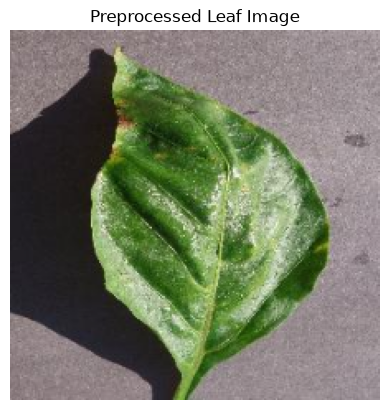

Image Shape: (224, 224, 3)
Minimum: 0.0
Maximum: 0.99607843


In [32]:
import cv2
import matplotlib.pyplot as plt
import os

# Select one training image
disease = classes[0]

folder = os.path.join(
    output_path, "train", disease
)

image_name = os.listdir(folder)[0]

image_path = os.path.join(folder, image_name)

# Read image
image = cv2.imread(image_path)

# Convert BGR to RGB
image = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

# Resize image
image = cv2.resize(image, (224, 224))

# Normalize image
image_normalized = image.astype("float32") / 255.0

# Display original processed image
plt.imshow(image_normalized)

plt.title("Preprocessed Leaf Image")

plt.axis("off")

plt.show()

print("Image Shape:", image_normalized.shape)
print("Minimum:", image_normalized.min())
print("Maximum:", image_normalized.max())

In [33]:
import tensorflow as tf

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    os.path.join(output_path, "train"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_data = tf.keras.utils.image_dataset_from_directory(
    os.path.join(output_path, "val"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_data = tf.keras.utils.image_dataset_from_directory(
    os.path.join(output_path, "test"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_data.class_names

print("Classes:", class_names)
print("Total Classes:", len(class_names))

Found 16443 files belonging to 15 classes.
Found 2056 files belonging to 15 classes.
Found 2062 files belonging to 15 classes.
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Total Classes: 15


In [34]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.15),

    layers.RandomZoom(0.1),

])

In [35]:
model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Normalize pixel values
    layers.Rescaling(1./255),

    # First CNN block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second CNN block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third CNN block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Fourth CNN block
    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )

])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,247 (1.61 MB)

 Trainable params: 423,247 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

In [37]:
early_stopping = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=4,

    restore_best_weights=True

)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(

    "best_plant_model.keras",

    monitor="val_loss",

    save_best_only=True

)

history = model.fit(

    train_data,

    validation_data=val_data,

    epochs=20,

    callbacks=[
        early_stopping,
        model_checkpoint
    ]

)

Epoch 1/20


c:\Users\yoush\OneDrive\Desktop\PlantDiseaseDetection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


514/514 ━━━━━━━━━━━━━━━━━━━━ 613s 1s/step - accuracy: 0.2573 - loss: 2.2550 - val_accuracy: 0.3589 - val_loss: 1.9433
Epoch 2/20
514/514 ━━━━━━━━━━━━━━━━━━━━ 555s 1s/step - accuracy: 0.4412 - loss: 1.7196 - val_accuracy: 0.5107 - val_loss: 1.5786
Epoch 3/20
514/514 ━━━━━━━━━━━━━━━━━━━━ 565s 1s/step - accuracy: 0.6012 - loss: 1.2185 - val_accuracy: 0.6479 - val_loss: 1.0049
Epoch 4/20
514/514 ━━━━━━━━━━━━━━━━━━━━ 560s 1s/step - accuracy: 0.6788 - loss: 0.9506 - val_accuracy: 0.6610 - val_loss: 1.0287
Epoch 5/20
514/514 ━━━━━━━━━━━━━━━━━━━━ 550s 1s/step - accuracy: 0.7270 - loss: 0.8064 - val_accuracy: 0.7675 - val_loss: 0.6685
Epoch 6/20
514/514 ━━━━━━━━━━━━━━━━━━━━ 564s 1s/step - accuracy: 0.7588 - loss: 0.7244 - val_accuracy: 0.7641 - val_loss: 0.6712
Epoch 7/20
514/514 ━━━━━━━━━━━━━━━━━━━━ 590s 1s/step - accuracy: 0.7865 - loss: 0.6457 - val_accuracy: 0.8478 - val_loss: 0.4578
Epoch 8/20
514/514 ━━━━━━━━━━━━━━━━━━━━ 667s 1s/step - accuracy: 0.8060 - loss: 0.5885 - val_accuracy: 0.794

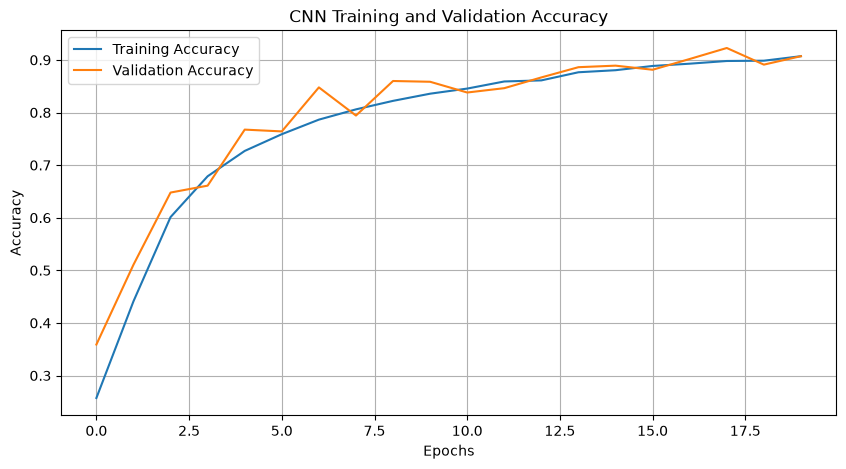

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

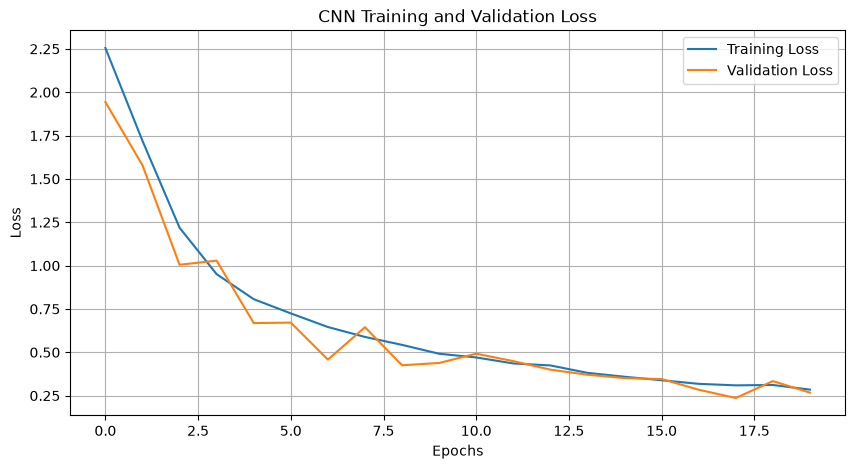

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

In [40]:
best_model = tf.keras.models.load_model(
    "best_plant_model.keras"
)

In [41]:
test_loss, test_accuracy = best_model.evaluate(test_data)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

65/65 ━━━━━━━━━━━━━━━━━━━━ 20s 290ms/step - accuracy: 0.9253 - loss: 0.4039
Test Loss: 0.4038902521133423
Test Accuracy: 92.53152012825012 %


In [42]:
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_data
])

y_pred = np.argmax(
    best_model.predict(test_data),
    axis=1
)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

65/65 ━━━━━━━━━━━━━━━━━━━━ 16s 240ms/step
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.86      0.96      0.91        92
                     Pepper__bell___healthy       0.92      0.99      0.95       148
                      Potato___Early_blight       0.94      0.98      0.96       100
                       Potato___Late_blight       0.97      0.83      0.89       100
                           Potato___healthy       1.00      0.81      0.90        16
                      Tomato_Bacterial_spot       0.93      0.93      0.93       213
                        Tomato_Early_blight       0.77      0.99      0.86       100
                         Tomato_Late_blight       0.92      0.93      0.92       191
                           Tomato_Leaf_Mold       0.98      0.85      0.91        96
                  Tomato_Septoria_leaf_spot       0.96      0.87      0.91       178
Tomato_Spider_mites_Tw

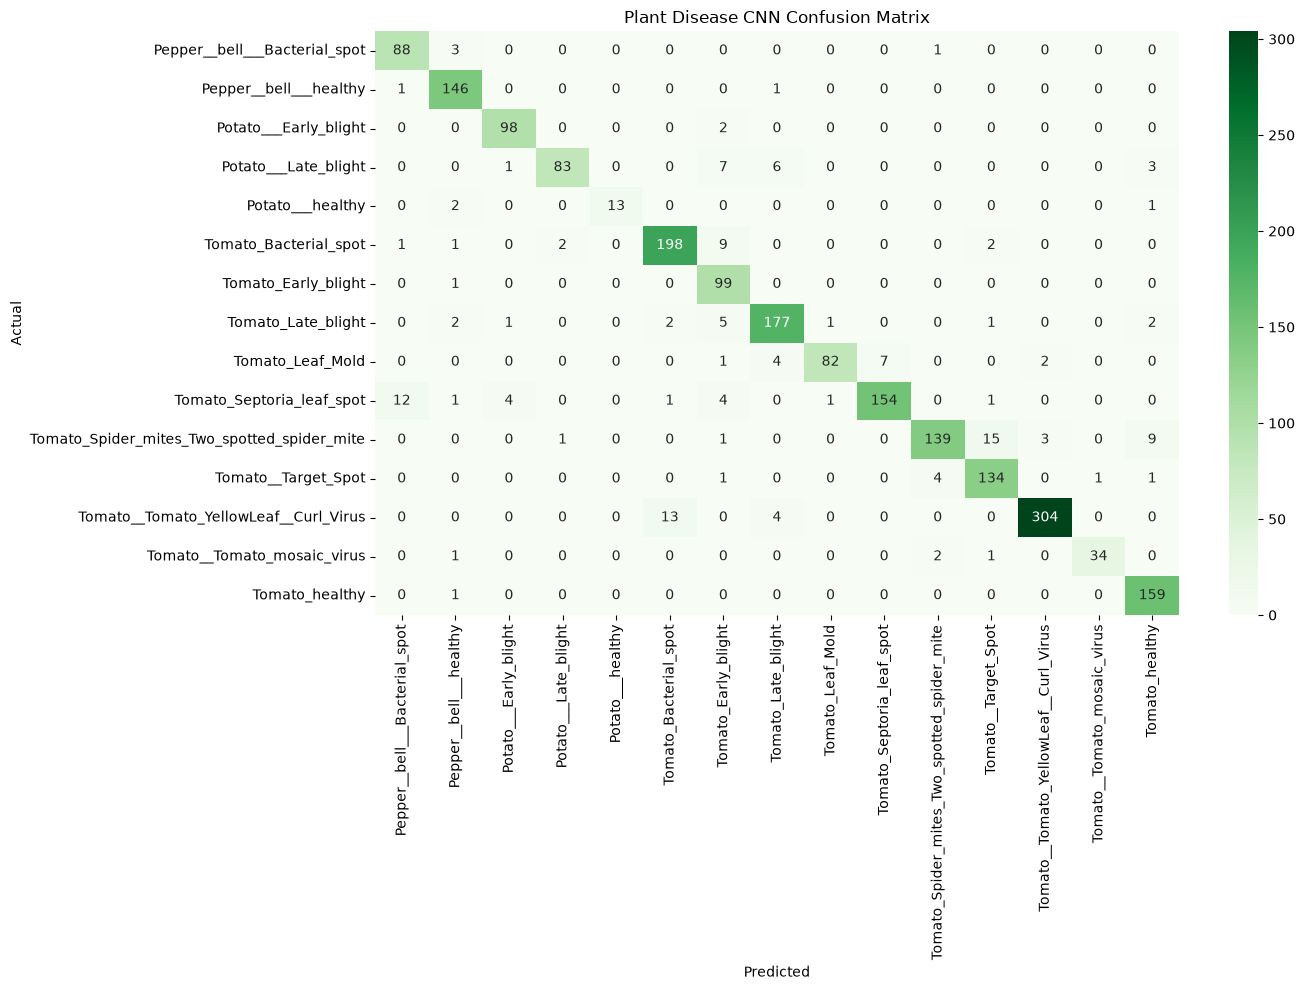

In [49]:
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Plant Disease CNN Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


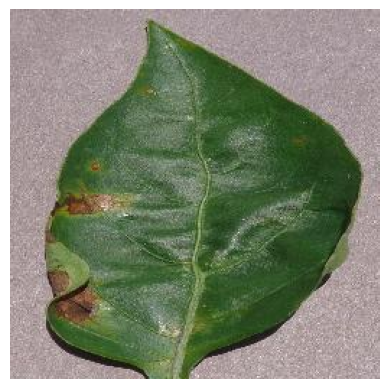

Predicted Disease: Pepper__bell___Bacterial_spot
Confidence: 97.79 %


In [54]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = r"C:\Users\yoush\OneDrive\Desktop\PlantDiseaseDetection\dataset_split\test\Pepper__bell___Bacterial_spot\14a96020-2720-43c5-8638-e70b90ebd573___JR_B.Spot 9039.JPG"

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image not found!")

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

resized_image = cv2.resize(
    image_rgb,
    (224, 224)
)

input_image = np.expand_dims(
    resized_image,
    axis=0
)

prediction = best_model.predict(input_image)

predicted_index = np.argmax(prediction[0])

predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

plt.imshow(image_rgb)
plt.axis("off")
plt.show()

print("Predicted Disease:", predicted_class)
print("Confidence:", round(float(confidence), 2), "%")

In [57]:
import os
import json

os.makedirs("models", exist_ok=True)

best_model.save(
    "models/plant_disease_model.keras"
)

with open("models/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Model saved successfully!")

Model saved successfully!


In [58]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [59]:
AUTOTUNE = tf.data.AUTOTUNE

train_mobilenet = train_data.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_mobilenet = val_data.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_mobilenet = test_data.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

In [60]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 7s 1us/step
MobileNetV2 loaded successfully!
Total layers: 154


In [61]:
inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

mobilenet_model = models.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "functional_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [62]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_mobilenet_model.keras",
    monitor="val_loss",
    save_best_only=True
)

mobilenet_history = mobilenet_model.fit(
    train_mobilenet,
    validation_data=val_mobilenet,
    epochs=15,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/15


c:\Users\yoush\OneDrive\Desktop\PlantDiseaseDetection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


514/514 ━━━━━━━━━━━━━━━━━━━━ 625s 1s/step - accuracy: 0.7479 - loss: 0.8015 - val_accuracy: 0.8813 - val_loss: 0.3924
Epoch 2/15
514/514 ━━━━━━━━━━━━━━━━━━━━ 550s 1s/step - accuracy: 0.8677 - loss: 0.4104 - val_accuracy: 0.9042 - val_loss: 0.3170
Epoch 3/15
514/514 ━━━━━━━━━━━━━━━━━━━━ 547s 1s/step - accuracy: 0.8931 - loss: 0.3321 - val_accuracy: 0.9183 - val_loss: 0.2690
Epoch 4/15
514/514 ━━━━━━━━━━━━━━━━━━━━ 582s 1s/step - accuracy: 0.8995 - loss: 0.3017 - val_accuracy: 0.9193 - val_loss: 0.2546
Epoch 5/15
514/514 ━━━━━━━━━━━━━━━━━━━━ 563s 1s/step - accuracy: 0.9053 - loss: 0.2835 - val_accuracy: 0.9236 - val_loss: 0.2465
Epoch 6/15
514/514 ━━━━━━━━━━━━━━━━━━━━ 549s 1s/step - accuracy: 0.9135 - loss: 0.2623 - val_accuracy: 0.9290 - val_loss: 0.2349
Epoch 7/15
514/514 ━━━━━━━━━━━━━━━━━━━━ 558s 1s/step - accuracy: 0.9171 - loss: 0.2474 - val_accuracy: 0.9246 - val_loss: 0.2367
Epoch 8/15
514/514 ━━━━━━━━━━━━━━━━━━━━ 543s 1s/step - accuracy: 0.9178 - loss: 0.2394 - val_accuracy: 0.930

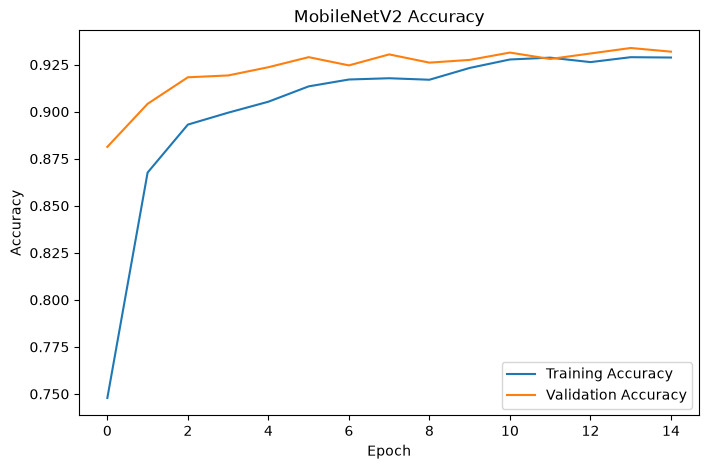

In [63]:
plt.figure(figsize=(8, 5))

plt.plot(
    mobilenet_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    mobilenet_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [64]:
mobilenet_model = tf.keras.models.load_model(
    "best_mobilenet_model.keras"
)

test_loss, test_accuracy = mobilenet_model.evaluate(test_mobilenet)

print("MobileNetV2 Test Accuracy:", round(test_accuracy * 100, 2), "%")

65/65 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.9176 - loss: 0.2489
MobileNetV2 Test Accuracy: 91.76 %


In [65]:
cnn_loss, cnn_accuracy = best_model.evaluate(test_data)

mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(test_mobilenet)

print("Custom CNN Accuracy:", round(cnn_accuracy * 100, 2), "%")
print("MobileNetV2 Accuracy:", round(mobilenet_accuracy * 100, 2), "%")

65/65 ━━━━━━━━━━━━━━━━━━━━ 20s 293ms/step - accuracy: 0.9253 - loss: 0.4039
65/65 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.9176 - loss: 0.2489
Custom CNN Accuracy: 92.53 %
MobileNetV2 Accuracy: 91.76 %


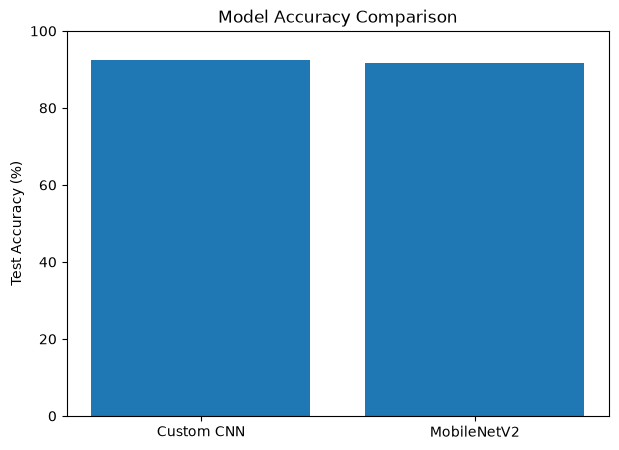

In [66]:
models_names = ["Custom CNN", "MobileNetV2"]
accuracies = [
    cnn_accuracy * 100,
    mobilenet_accuracy * 100
]

plt.figure(figsize=(7, 5))
plt.bar(models_names, accuracies)
plt.title("Model Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.show()

In [67]:
import os
import json

os.makedirs("models", exist_ok=True)

mobilenet_model.save("models/plant_mobilenet_model.keras")

with open("models/class_names.json", "w") as file:
    json.dump(class_names, file)

print("Model and class names saved successfully!")

Model and class names saved successfully!
